<a href="https://colab.research.google.com/github/muskankh/Satellite-vit-project/blob/main/02_linear_probe_clip_dinov2_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Satellite Image Classification with Vision Transformers
## Notebook 2: Linear Probe on Frozen CLIP and DINOv2 Embeddings

**What is a linear probe?** We keep a pre-trained model **frozen** (no retraining), turn every image into an embedding (a list of numbers), and train only a very simple classifier (logistic regression) on top. If the probe does well, the model's features already contain the information needed for the task.

**Why do it?** In Notebook 1, zero-shot CLIP scored 74.6%, below a colour-only baseline (82.4%). Now we test whether CLIP's *features* are good once we give it a little supervision, and compare them with **DINOv2** (self-supervised, never saw any text).

**Steps in this notebook**
1. Load your `split.csv` and re-link it to the images
2. Load (or compute) CLIP and DINOv2 embeddings
3. Train logistic regression probes, choosing the regularisation strength on **validation only**
4. Evaluate **once** on the test set (accuracy, macro-F1, 95% bootstrap CIs, confusion matrices)
5. Paired comparison: is one model really better, or is it noise?
6. Training-size ablation (learning curve)
7. Error analysis, then save everything

**Models**
| Model | Type | Embedding size |
|---|---|---|
| `openai/clip-vit-base-patch32` | language-supervised | 512 |
| `facebook/dinov2-base` | self-supervised | 1536 (CLS token + mean of patch tokens) |

## 0. Setup

**Before you start:** `Runtime -> Change runtime type -> T4 GPU`.
You need two files in Colab. **The easiest way is to drag both into the Files panel** (folder icon on the left):
- `split.csv` (from Notebook 1)
- `data-2.zip` (your images)

You can also keep them in Google Drive. The notebook searches both places.

In [6]:
!pip install -q transformers scikit-learn matplotlib pandas tqdm

In [7]:
import os, json, random, zipfile, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

# ---------------- CONFIG ----------------
SEED     = 42
WORK_DIR = Path("/content/work")
OUT_DIR  = Path("/content/outputs_nb2")
DRIVE_BACKUP_DIR = Path("/content/drive/MyDrive/satellite_project")   # results are copied here at the end
# ----------------------------------------

FIG_DIR = OUT_DIR / "figures"
EMB_DIR = OUT_DIR / "embeddings"
for d in (WORK_DIR, OUT_DIR, FIG_DIR, EMB_DIR):
    d.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED)

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab - skipping Drive mount.")
print("Setup OK")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup OK


## 1. Load `split.csv` and the images

`split.csv` stores where each image was **in your previous session** (`/content/work/...`). Colab wipes its files between sessions, so we unzip the images again and re-link every row by class folder and file name (it works whatever the folder is called inside your zip).

**Critical:** we use the **exact same split** as Notebook 1, so all models are compared on identical train/val/test images.

In [8]:
SEARCH_DIRS = ["/content", "/content/outputs", "/content/drive/MyDrive",
               "/content/drive/MyDrive/satellite_project", "/content/drive/MyDrive/Colab Notebooks"]

def find_file(patterns, what):
    for folder in SEARCH_DIRS:
        f = Path(folder)
        if not f.exists():
            continue
        for pat in patterns:
            hits = sorted(f.glob(pat))
            if hits:
                print(f"Found {what}: {hits[0]}")
                return hits[0]
    raise FileNotFoundError(
        f"Could not find {what}.\n"
        "FIX: click the folder icon on the LEFT of Colab, drag the file into the Files panel, "
        "wait for the upload to finish, then re-run this cell.")

SPLIT_CSV = find_file(["split.csv", "split*.csv"], "split.csv")
ZIP_FILE  = find_file(["data-2.zip", "data*.zip"], "your image zip")

EXTRACT_DIR = WORK_DIR / "images"

# 1) Unzip into a clean folder (skip Mac junk files). Re-extract if the folder is missing or has no images.
IMG_EXT = (".jpg", ".jpeg", ".png")
def list_images(folder):
    return [p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXT and not p.name.startswith("._")]

if EXTRACT_DIR.exists():
    shutil.rmtree(EXTRACT_DIR)          # always start clean: stale folders from failed attempts must not be reused
EXTRACT_DIR.mkdir(parents=True)
with zipfile.ZipFile(ZIP_FILE) as z:
    keep = [m for m in z.namelist()
            if not m.startswith("__MACOSX") and "/._" not in m and not m.endswith(".DS_Store")]
    z.extractall(EXTRACT_DIR, members=keep)

files = list_images(EXTRACT_DIR)
print("Image files found after unzipping:", len(files))
if not files:
    raise FileNotFoundError("The zip contains no images. Check that you uploaded the right zip file.")

# 2) Re-link every row of split.csv to the real file, wherever the zip put it
df = pd.read_csv(SPLIT_CSV)
index   = {(p.parent.name.lower(), p.name.lower()): p for p in files}      # (class folder, file name)
by_name = {}
for p in files:
    by_name.setdefault(p.name.lower(), []).append(p)

new_paths = []
for c, p in zip(df["cls"], df["path"]):
    name = Path(p).name.lower()
    hit = index.get((str(c).lower(), name))
    if hit is None and len(by_name.get(name, [])) == 1:                    # fall back to file name alone
        hit = by_name[name][0]
    new_paths.append(str(hit) if hit is not None else None)
df["path"] = new_paths

n_missing = int(df["path"].isna().sum())
if n_missing:
    print(f"\nPROBLEM: {n_missing} of {len(df)} images from split.csv were not found in the zip.")
    print("Folders in zip      :", sorted({p.parent.name for p in files})[:10])
    print("Example zip files   :", sorted(p.name for p in files)[:5])
    print("Example split.csv   :", [Path(p).name for p in pd.read_csv(SPLIT_CSV)["path"].head(5)])
    print("Zip file used       :", ZIP_FILE, f"({Path(ZIP_FILE).stat().st_size / 1e6:.1f} MB)")
    raise AssertionError("The zip does not match split.csv. Make sure you upload the SAME data-2.zip you used in Notebook 1 "
                         "(about 25 MB, 5,631 images), and delete any other data*.zip files from the Files panel.")

CLASS_NAMES = sorted(df["cls"].unique())
y = df["label"].values
idx_train = np.where(df["split"] == "train")[0]
idx_val   = np.where(df["split"] == "val")[0]
idx_test  = np.where(df["split"] == "test")[0]
print("Classes:", CLASS_NAMES)
print(f"train={len(idx_train)}  val={len(idx_val)}  test={len(idx_test)}   (Notebook 1 gave 3942 / 846 / 843)")
df[["cls", "split"]].value_counts().unstack()

Found split.csv: /content/split.csv
Found your image zip: /content/drive/MyDrive/data-2.zip
Image files found after unzipping: 5631
Classes: ['cloudy', 'desert', 'green_area', 'water']
train=3942  val=846  test=843   (Notebook 1 gave 3942 / 846 / 843)


split,test,train,val
cls,,,
cloudy,225,1050,225
desert,170,788,173
green_area,225,1050,225
water,223,1054,223


## 2. Get the embeddings

For each model we look for a saved file first (so nothing is recomputed). If not found, we compute it (about 1-3 minutes on a T4 GPU) and save it.

**Pre-processing:** both models use their own official processors. CLIP resizes to 224x224. DINOv2 resizes the short side to 256 and centre-crops 224x224. The 64x64 images (green_area, water) are therefore upscaled, which makes them blurry. Mention this in your report.

**DINOv2 embedding:** we concatenate the `[CLS]` token with the average of all patch tokens, which is the standard recipe for linear evaluation.

In [9]:
def embeddings_look_valid(arr):
    """Real embeddings vary between images. All-zero, constant or NaN arrays are placeholders, never real."""
    return bool(np.isfinite(arr).all() and np.abs(arr).max() > 0 and arr.std(axis=0).mean() > 1e-6)

def try_load_embeddings(filename):
    """Look for a saved embedding file in the usual places; accept it only if it matches our table."""
    for folder in [EMB_DIR, Path("/content/outputs/embeddings"), Path("/content"),
                   Path("/content/drive/MyDrive"), DRIVE_BACKUP_DIR, DRIVE_BACKUP_DIR / "embeddings"]:
        f = folder / filename
        if f.exists():
            arr = np.load(f)
            if not embeddings_look_valid(arr):
                print(f"Ignoring {f}: values are all zero, constant or NaN (a dummy/broken file) -> will recompute")
                continue
            if arr.shape[0] == len(df):
                print(f"Loaded {filename} from {folder}: {arr.shape}")
                return arr
            print(f"Ignoring {f}: has {arr.shape[0]} rows, expected {len(df)}")
    return None

DEVICE = None
def get_device():
    global DEVICE
    if DEVICE is None:
        import torch
        DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
        print("Device:", DEVICE)
        if DEVICE == "cpu":
            print("WARNING: no GPU. Use Runtime -> Change runtime type -> T4 GPU.")
    return DEVICE

In [11]:
# ---------------- CLIP ----------------
EMB_CLIP = try_load_embeddings("clip_b32_images.npy")

if EMB_CLIP is None:
    import torch
    from transformers import CLIPModel, CLIPProcessor
    torch.manual_seed(SEED)
    dev = get_device()
    m = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(dev).eval()
    proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

    feats = []
    paths = df["path"].tolist()
    with torch.no_grad():
        for i in tqdm(range(0, len(paths), 64), desc="CLIP embeddings"):
            imgs = [Image.open(p).convert("RGB") for p in paths[i:i + 64]]
            inp = proc(images=imgs, return_tensors="pt").to(dev)
            f = m.get_image_features(**inp)
            f = f if isinstance(f, torch.Tensor) else f.pooler_output
            feats.append(torch.nn.functional.normalize(f, dim=-1).cpu())
    EMB_CLIP = torch.cat(feats).numpy()
    np.save(EMB_DIR / "clip_b32_images.npy", EMB_CLIP)
    del m; torch.cuda.empty_cache()
    print("Saved CLIP embeddings:", EMB_CLIP.shape)

assert EMB_CLIP.shape[0] == len(df)

Loaded clip_b32_images.npy from /content/outputs_nb2/embeddings: (5631, 512)


In [ ]:
# ---------------- DINOv2 ----------------
EMB_DINO = try_load_embeddings("dinov2_base_images.npy")

if EMB_DINO is None:
    import torch
    from transformers import AutoModel, AutoImageProcessor
    torch.manual_seed(SEED)
    dev = get_device()
    m = AutoModel.from_pretrained("facebook/dinov2-base").to(dev).eval()
    proc = AutoImageProcessor.from_pretrained("facebook/dinov2-base")

    feats = []
    paths = df["path"].tolist()
    with torch.no_grad():
        for i in tqdm(range(0, len(paths), 64), desc="DINOv2 embeddings"):
            imgs = [Image.open(p).convert("RGB") for p in paths[i:i + 64]]
            inp = proc(images=imgs, return_tensors="pt").to(dev)
            h = m(**inp).last_hidden_state                         # (batch, tokens, 768)
            f = torch.cat([h[:, 0], h[:, 1:].mean(dim=1)], dim=1)   # CLS + mean patch -> 1536
            feats.append(f.cpu())
    EMB_DINO = torch.cat(feats).numpy()
    np.save(EMB_DIR / "dinov2_base_images.npy", EMB_DINO)
    del m; torch.cuda.empty_cache()
    print("Saved DINOv2 embeddings:", EMB_DINO.shape)

assert EMB_DINO.shape[0] == len(df)
EMBEDDINGS = {"CLIP ViT-B/32": EMB_CLIP, "DINOv2 ViT-B/14": EMB_DINO}
for k, v in EMBEDDINGS.items():
    print(f"{k:16s} embedding shape: {v.shape}")

# SANITY CHECK: nearest-class-centroid accuracy on validation (no training, ~instant).
# Real embeddings score far above chance (25%). A score near 25% means the embeddings are fake or misaligned.
for k, v in EMBEDDINGS.items():
    z = (v - v[idx_train].mean(0)) / (v[idx_train].std(0) + 1e-8)
    cent = np.stack([z[idx_train][y[idx_train] == c].mean(0) for c in range(len(CLASS_NAMES))])
    acc_c = (np.argmin(((z[idx_val][:, None, :] - cent[None]) ** 2).sum(-1), axis=1) == y[idx_val]).mean()
    print(f"Sanity check {k:16s}: nearest-centroid val accuracy = {acc_c:.3f}", "OK" if acc_c > 0.5 else "<-- SUSPICIOUS, embeddings may be wrong")

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

DINOv2 embeddings:   0%|          | 0/88 [00:00<?, ?it/s]

## 3. Train the linear probes

**Procedure (important for validity)**
1. Standardise features (zero mean, unit variance), with statistics learnt from the **train set only**.
2. Try several values of `C` (regularisation strength: small `C` = simpler model) and train each on the train set.
3. Pick the `C` with the best **validation macro-F1**.
4. Evaluate the chosen model **once** on the test set.

The test set is never used to make any choice.

In [13]:
C_GRID = [0.001, 0.01, 0.1, 1, 10, 100]

def make_probe(C):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000))

def macro_f1(a, b):
    return f1_score(a, b, average="macro")

def bootstrap_ci(y_true, y_pred, metric, n_boot=1000, seed=SEED):
    rng = np.random.RandomState(seed)
    n = len(y_true)
    s = [metric(y_true[ix], y_pred[ix]) for ix in (rng.randint(0, n, n) for _ in range(n_boot))]
    return np.percentile(s, [2.5, 97.5])

PROBES, PRED_TEST, C_TABLES = {}, {}, {}

for name, E in EMBEDDINGS.items():
    rows = []
    for C in C_GRID:
        p = make_probe(C).fit(E[idx_train], y[idx_train])
        pv = p.predict(E[idx_val])
        rows.append(dict(C=C, val_acc=accuracy_score(y[idx_val], pv), val_macro_f1=macro_f1(y[idx_val], pv)))
    t = pd.DataFrame(rows)
    C_TABLES[name] = t
    best_C = t.sort_values("val_macro_f1", ascending=False).iloc[0]["C"]
    PROBES[name] = (make_probe(best_C).fit(E[idx_train], y[idx_train]), best_C)
    PRED_TEST[name] = PROBES[name][0].predict(E[idx_test])
    print(f"\n=== {name}: validation results for each C ===")
    print(t.round(4).to_string(index=False))
    print(f"-> chosen C = {best_C} (best validation macro-F1)")


=== CLIP ViT-B/32: validation results for each C ===
      C  val_acc  val_macro_f1
  0.001   0.9988        0.9989
  0.010   1.0000        1.0000
  0.100   0.9988        0.9989
  1.000   0.9988        0.9989
 10.000   0.9988        0.9989
100.000   0.9988        0.9989
-> chosen C = 0.01 (best validation macro-F1)

=== DINOv2 ViT-B/14: validation results for each C ===
      C  val_acc  val_macro_f1
  0.001   0.9929        0.9933
  0.010   0.9976        0.9978
  0.100   0.9976        0.9978
  1.000   0.9976        0.9978
 10.000   0.9976        0.9978
100.000   0.9976        0.9978
-> chosen C = 0.01 (best validation macro-F1)


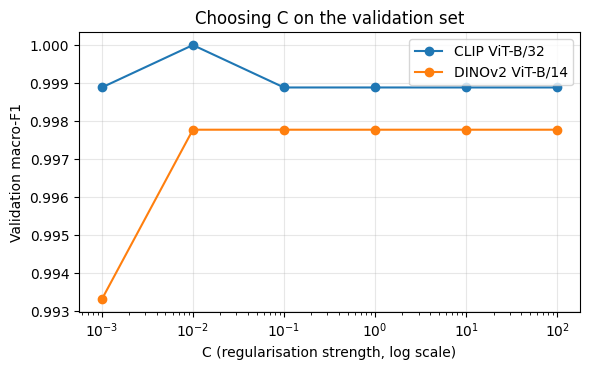

In [14]:
# Plot validation score against C (shows the model is not sensitive / not under- or over-regularised)
fig, ax = plt.subplots(figsize=(6, 3.8))
for name, t in C_TABLES.items():
    ax.plot(t["C"], t["val_macro_f1"], marker="o", label=name)
ax.set_xscale("log"); ax.set_xlabel("C (regularisation strength, log scale)")
ax.set_ylabel("Validation macro-F1"); ax.set_title("Choosing C on the validation set")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "08_probe_C_selection.png", dpi=150); plt.show()

## 4. Final test evaluation (done once)

We now report accuracy and macro-F1 with 95% bootstrap confidence intervals, and compare to everything from Notebook 1.

In [15]:
y_test = y[idx_test]
rows = []

# Zero-shot CLIP result from Notebook 1 (fill in your own numbers if the JSON is not available)
zs = dict(acc=0.7461, acc_lo=0.7153, acc_hi=0.7758, f1=0.7482, f1_lo=0.7157, f1_hi=0.7765)
for folder in SEARCH_DIRS + ["/content/outputs"]:
    jf = Path(folder) / "results_notebook1.json"
    if jf.exists():
        r = json.load(open(jf))["zero_shot_clip_b32"]
        zs = dict(acc=r["test_accuracy"], acc_lo=r["test_accuracy_ci95"][0], acc_hi=r["test_accuracy_ci95"][1],
                  f1=r["test_macro_f1"], f1_lo=r["test_macro_f1_ci95"][0], f1_hi=r["test_macro_f1_ci95"][1])
        print("Loaded Notebook 1 results from", jf)
        break
rows.append(dict(Method="Zero-shot CLIP (Notebook 1)", Accuracy=zs["acc"], Acc_CI=(zs["acc_lo"], zs["acc_hi"]),
                 Macro_F1=zs["f1"], F1_CI=(zs["f1_lo"], zs["f1_hi"])))

for name, pred in PRED_TEST.items():
    a, f = accuracy_score(y_test, pred), macro_f1(y_test, pred)
    rows.append(dict(Method=f"Linear probe: {name}", Accuracy=a, Acc_CI=tuple(bootstrap_ci(y_test, pred, accuracy_score)),
                     Macro_F1=f, F1_CI=tuple(bootstrap_ci(y_test, pred, macro_f1))))

results_df = pd.DataFrame(rows)
display_df = results_df.copy()
display_df["Accuracy"] = [f"{a:.4f}  ({lo:.3f}-{hi:.3f})" for a, (lo, hi) in zip(results_df["Accuracy"], results_df["Acc_CI"])]
display_df["Macro_F1"] = [f"{a:.4f}  ({lo:.3f}-{hi:.3f})" for a, (lo, hi) in zip(results_df["Macro_F1"], results_df["F1_CI"])]
print("TEST SET RESULTS (n =", len(idx_test), "), 95% bootstrap CI in brackets")
print("Baselines from Notebook 1: chance 0.25 | image-size-only 0.533 | colour-only (mean RGB) 0.824\n")
display_df[["Method", "Accuracy", "Macro_F1"]]

TEST SET RESULTS (n = 843 ), 95% bootstrap CI in brackets
Baselines from Notebook 1: chance 0.25 | image-size-only 0.533 | colour-only (mean RGB) 0.824



,Method,Accuracy,Macro_F1
0,Zero-shot CLIP (Notebook 1),0.7461 (0.715-0.776),0.7482 (0.716-0.776)
1,Linear probe: CLIP ViT-B/32,0.9988 (0.995-1.000),0.9989 (0.996-1.000)
2,Linear probe: DINOv2 ViT-B/14,0.9964 (0.992-1.000),0.9967 (0.992-1.000)


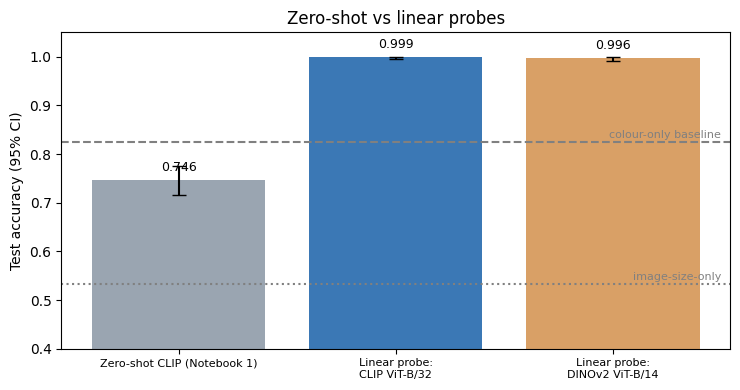

In [16]:
# Bar chart with confidence intervals + baseline lines
fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(len(results_df))
acc = results_df["Accuracy"].values
err = np.array([[a - lo, hi - a] for a, (lo, hi) in zip(acc, results_df["Acc_CI"])]).T
ax.bar(x, acc, yerr=err, capsize=5, color=["#9aa5b1", "#3b78b5", "#d9a066"][:len(x)])
for xi, a in zip(x, acc):
    ax.text(xi, a + 0.02, f"{a:.3f}", ha="center", fontsize=9)
ax.axhline(0.824, ls="--", color="grey"); ax.text(len(x) - 0.5, 0.832, "colour-only baseline", ha="right", fontsize=8, color="grey")
ax.axhline(0.533, ls=":", color="grey");  ax.text(len(x) - 0.5, 0.541, "image-size-only", ha="right", fontsize=8, color="grey")
ax.set_xticks(x); ax.set_xticklabels([m.replace(": ", ":\n") for m in results_df["Method"]], fontsize=8)
ax.set_ylim(0.4, 1.05); ax.set_ylabel("Test accuracy (95% CI)")
ax.set_title("Zero-shot vs linear probes")
plt.tight_layout(); plt.savefig(FIG_DIR / "09_probe_results.png", dpi=150); plt.show()


===== CLIP ViT-B/32 =====
              precision    recall  f1-score   support

      cloudy      1.000     1.000     1.000       225
      desert      1.000     1.000     1.000       170
  green_area      1.000     0.996     0.998       225
       water      0.996     1.000     0.998       223

    accuracy                          0.999       843
   macro avg      0.999     0.999     0.999       843
weighted avg      0.999     0.999     0.999       843


===== DINOv2 ViT-B/14 =====
              precision    recall  f1-score   support

      cloudy      1.000     1.000     1.000       225
      desert      1.000     1.000     1.000       170
  green_area      0.996     0.991     0.993       225
       water      0.991     0.996     0.993       223

    accuracy                          0.996       843
   macro avg      0.997     0.997     0.997       843
weighted avg      0.996     0.996     0.996       843



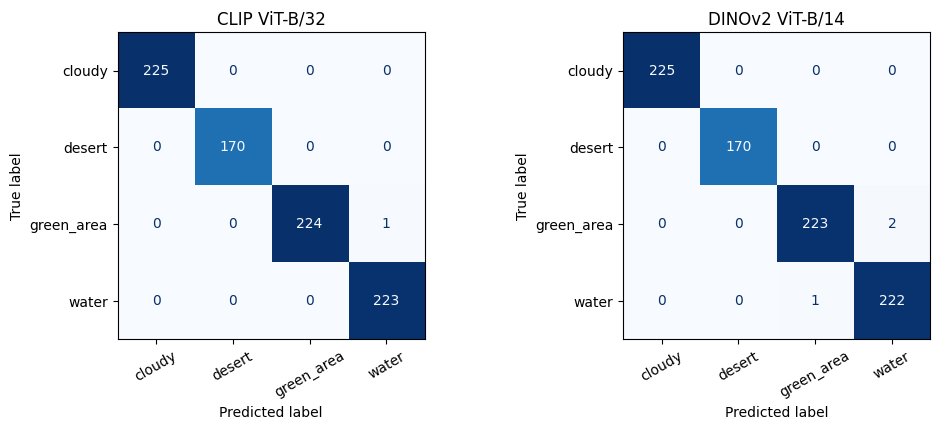

In [17]:
# Per-class report and confusion matrices
fig, axes = plt.subplots(1, len(PRED_TEST), figsize=(5.2 * len(PRED_TEST), 4.4))
axes = np.atleast_1d(axes)
for ax, (name, pred) in zip(axes, PRED_TEST.items()):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=30)
    ax.set_title(name)
    print(f"\n===== {name} =====")
    print(classification_report(y_test, pred, target_names=CLASS_NAMES, digits=3))
plt.tight_layout(); plt.savefig(FIG_DIR / "10_probe_confusion.png", dpi=150); plt.show()

## 5. Is one model really better? (paired bootstrap)

The two probes are tested on the **same** 843 images, so we can compare them directly. We resample the test images 2,000 times, compute the accuracy difference each time, and see whether the 95% interval of the difference **excludes zero**.

- Interval excludes 0 -> the difference is unlikely to be chance (you can say "model A is better").
- Interval includes 0 -> you **cannot** claim a difference. Say so in the report; it is still a valid result.

In [18]:
def paired_bootstrap_diff(y_true, pred_a, pred_b, n_boot=2000, seed=SEED):
    rng = np.random.RandomState(seed)
    n = len(y_true)
    ca, cb = (pred_a == y_true).astype(float), (pred_b == y_true).astype(float)
    diffs = np.array([(ca[ix] - cb[ix]).mean() for ix in (rng.randint(0, n, n) for _ in range(n_boot))])
    return (ca - cb).mean(), np.percentile(diffs, [2.5, 97.5])

names = list(PRED_TEST)
a, b = names[0], names[1]
d, (lo, hi) = paired_bootstrap_diff(y_test, PRED_TEST[a], PRED_TEST[b])
print(f"Accuracy({a}) - Accuracy({b}) = {d:+.4f}   95% CI [{lo:+.4f}, {hi:+.4f}]")
print("Significant difference (CI excludes 0)?", "YES" if (lo > 0 or hi < 0) else "NO")

# Disagreement table: where exactly do they differ?
ca, cb = PRED_TEST[a] == y_test, PRED_TEST[b] == y_test
print(f"\nBoth correct: {(ca & cb).sum()} | only {a}: {(ca & ~cb).sum()} | only {b}: {(~ca & cb).sum()} | both wrong: {(~ca & ~cb).sum()}")

Accuracy(CLIP ViT-B/32) - Accuracy(DINOv2 ViT-B/14) = +0.0024   95% CI [-0.0024, +0.0071]
Significant difference (CI excludes 0)? NO

Both correct: 839 | only CLIP ViT-B/32: 3 | only DINOv2 ViT-B/14: 1 | both wrong: 0


## 6. How much labelled data do we need? (learning curve)

We train the probe on only 2%, 5%, 10%, 25%, 50% and 100% of the training set (3 random subsets each) and measure accuracy on the **validation** set. (We use validation, not test, so the test set stays untouched.)

**Why it matters:** a model whose features are already good needs very few labels. This is a key practical advantage of pre-trained models, and a good figure for your report.

CLIP ViT-B/32:   0%|          | 0/6 [00:00<?, ?it/s]

DINOv2 ViT-B/14:   0%|          | 0/6 [00:00<?, ?it/s]

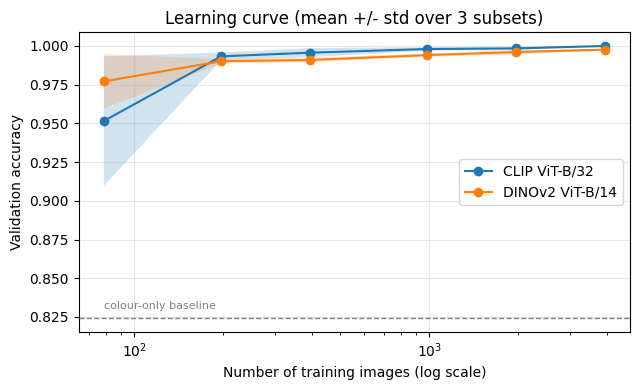


Validation accuracy (mean) by training size:
      CLIP ViT-B/32  DINOv2 ViT-B/14
78           0.9515           0.9771
197          0.9933           0.9901
394          0.9957           0.9909
985          0.9980           0.9941
1971         0.9984           0.9961
3942         1.0000           0.9976


In [19]:
FRACTIONS = [0.02, 0.05, 0.10, 0.25, 0.50, 1.00]
N_REPEATS = 3
curve = {name: {f: [] for f in FRACTIONS} for name in EMBEDDINGS}

for name, E in EMBEDDINGS.items():
    best_C = PROBES[name][1]
    for f in tqdm(FRACTIONS, desc=name):
        for rep in range(N_REPEATS):
            if f < 1.0:
                sub, _ = train_test_split(idx_train, train_size=f, stratify=y[idx_train], random_state=SEED + rep)
            else:
                sub = idx_train
            p = make_probe(best_C).fit(E[sub], y[sub])
            curve[name][f].append(accuracy_score(y[idx_val], p.predict(E[idx_val])))

fig, ax = plt.subplots(figsize=(6.5, 4))
for name in EMBEDDINGS:
    m = np.array([np.mean(curve[name][f]) for f in FRACTIONS])
    s = np.array([np.std(curve[name][f]) for f in FRACTIONS])
    xs = [f * len(idx_train) for f in FRACTIONS]
    ax.plot(xs, m, marker="o", label=name)
    ax.fill_between(xs, m - s, m + s, alpha=0.2)
ax.set_xscale("log"); ax.set_xlabel("Number of training images (log scale)")
ax.set_ylabel("Validation accuracy"); ax.set_title("Learning curve (mean +/- std over 3 subsets)")
ax.axhline(0.824, ls="--", color="grey", lw=1); ax.text(xs[0], 0.83, "colour-only baseline", fontsize=8, color="grey")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "11_learning_curve.png", dpi=150); plt.show()

print("\nValidation accuracy (mean) by training size:")
print(pd.DataFrame({name: {int(f * len(idx_train)): np.mean(v) for f, v in curve[name].items()} for name in EMBEDDINGS}).round(4))

## 7. Error analysis

Numbers alone do not earn top marks, so we look at the actual mistakes of the better probe. **Your task:** categorise 30-50 of them by hand, e.g.
- ambiguous image (mixed land and water, clouds over sea)
- dark or blurry (very common for the 64x64 images)
- label looks wrong (possible label noise)
- real model failure on a clear image

Write the counts in your report.

Best probe: CLIP ViT-B/32 | 1 errors out of 843

Most frequent confusions (true -> predicted):
  green_area -> water      1


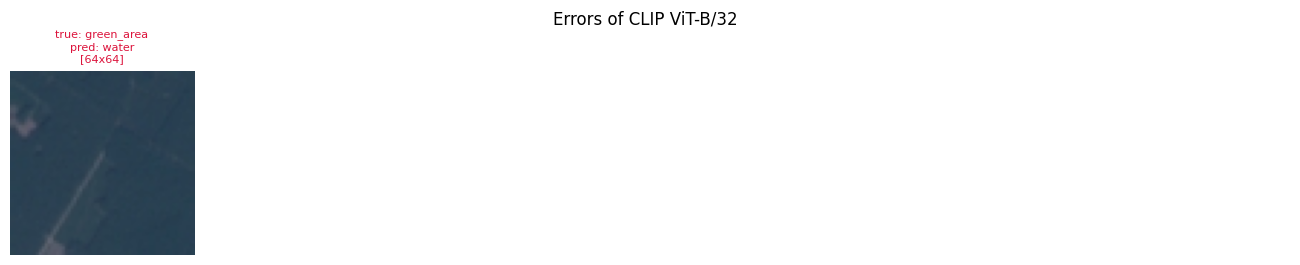


Error rate by image size (test set):
         error_rate  n_errors  n_images
size                                   
256x256      0.0000         0       395
64x64        0.0022         1       448


In [20]:
best_name = max(PRED_TEST, key=lambda n: accuracy_score(y_test, PRED_TEST[n]))
pred = PRED_TEST[best_name]
wrong_pos = np.where(pred != y_test)[0]
print(f"Best probe: {best_name} | {len(wrong_pos)} errors out of {len(y_test)}")

# Which class pairs are confused most?
cm = confusion_matrix(y_test, pred)
pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], cm[i, j]) for i in range(len(cm)) for j in range(len(cm)) if i != j and cm[i, j] > 0]
print("\nMost frequent confusions (true -> predicted):")
for t, p, n in sorted(pairs, key=lambda x: -x[2])[:5]:
    print(f"  {t:10s} -> {p:10s} {n}")

if len(wrong_pos):
    pick = np.random.RandomState(SEED).choice(wrong_pos, min(18, len(wrong_pos)), replace=False)
    cols = 6; rws = int(np.ceil(len(pick) / cols))
    fig, axes = plt.subplots(rws, cols, figsize=(2.2 * cols, 2.6 * rws))
    axes = np.atleast_1d(axes).flatten()
    for ax in axes: ax.axis("off")
    for ax, k in zip(axes, pick):
        i = idx_test[k]
        ax.imshow(Image.open(df.loc[i, "path"]).convert("RGB"))
        ax.set_title(f"true: {df.loc[i, 'cls']}\npred: {CLASS_NAMES[pred[k]]}\n[{df.loc[i, 'size']}]", fontsize=8, color="crimson")
    plt.suptitle(f"Errors of {best_name}", y=1.0)
    plt.tight_layout(); plt.savefig(FIG_DIR / "12_probe_errors.png", dpi=150); plt.show()

# Are errors concentrated in one image size? (hint of resolution effects; formal test in Notebook 4)
err_by_size = pd.DataFrame({"size": df.loc[idx_test, "size"].values, "wrong": pred != y_test}).groupby("size")["wrong"].agg(["mean", "sum", "count"])
err_by_size.columns = ["error_rate", "n_errors", "n_images"]
print("\nError rate by image size (test set):")
print(err_by_size.round(4))

## 8. Save results

Everything goes into a JSON file (copy numbers into the report from here) and is backed up to Google Drive, because Colab deletes its files when the session ends. **Keep `split.csv` and the embeddings: Notebooks 3 and 4 reuse them.**

In [21]:
results = {
    "seed": SEED,
    "n_test": int(len(idx_test)),
    "zero_shot_clip_from_notebook1": zs,
    "probes": {
        name: {
            "chosen_C": float(PROBES[name][1]),
            "test_accuracy": float(accuracy_score(y_test, PRED_TEST[name])),
            "test_accuracy_ci95": [float(v) for v in bootstrap_ci(y_test, PRED_TEST[name], accuracy_score)],
            "test_macro_f1": float(macro_f1(y_test, PRED_TEST[name])),
            "test_macro_f1_ci95": [float(v) for v in bootstrap_ci(y_test, PRED_TEST[name], macro_f1)],
        } for name in PRED_TEST
    },
    "paired_diff_acc": {"a": a, "b": b, "diff": float(d), "ci95": [float(lo), float(hi)]},
    "learning_curve_val_acc_mean": {n: {str(int(f * len(idx_train))): float(np.mean(v)) for f, v in curve[n].items()} for n in curve},
}
with open(OUT_DIR / "results_notebook2.json", "w") as f:
    json.dump(results, f, indent=2)
print(json.dumps(results, indent=2))

# Backup to Drive (also keeps split.csv safe for the next notebooks)
try:
    DRIVE_BACKUP_DIR.mkdir(parents=True, exist_ok=True)
    shutil.copytree(OUT_DIR, DRIVE_BACKUP_DIR / "outputs_nb2", dirs_exist_ok=True)
    shutil.copy(SPLIT_CSV, DRIVE_BACKUP_DIR / "split.csv")
    print("\nBacked up to Google Drive:", DRIVE_BACKUP_DIR)
except Exception as e:
    print("\nDrive backup skipped:", e)
shutil.make_archive("/content/notebook2_outputs", "zip", OUT_DIR)
print("Also created /content/notebook2_outputs.zip (download from the Files panel).")

{
  "seed": 42,
  "n_test": 843,
  "zero_shot_clip_from_notebook1": {
    "acc": 0.7461,
    "acc_lo": 0.7153,
    "acc_hi": 0.7758,
    "f1": 0.7482,
    "f1_lo": 0.7157,
    "f1_hi": 0.7765
  },
  "probes": {
    "CLIP ViT-B/32": {
      "chosen_C": 0.01,
      "test_accuracy": 0.9988137603795967,
      "test_accuracy_ci95": [
        0.9952550415183867,
        1.0
      ],
      "test_macro_f1": 0.9988839230106177,
      "test_macro_f1_ci95": [
        0.9956944243550901,
        1.0
      ]
    },
    "DINOv2 ViT-B/14": {
      "chosen_C": 0.01,
      "test_accuracy": 0.99644128113879,
      "test_accuracy_ci95": [
        0.9916963226571768,
        1.0
      ],
      "test_macro_f1": 0.996651769031853,
      "test_macro_f1_ci95": [
        0.9922732783903923,
        1.0
      ]
    }
  },
  "paired_diff_acc": {
    "a": "CLIP ViT-B/32",
    "b": "DINOv2 ViT-B/14",
    "diff": 0.002372479240806643,
    "ci95": [
      -0.002372479240806643,
      0.0071174377224199285
    ]
  },